# Most "jumps" are not jumps

**Jumps in financial time series, post 1 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| **1** | **Most "jumps" are not jumps** |
| 2 | Intraday seasonality and false jumps |
| 3 | Bid-ask bounce and microstructure noise |
| 4 | Finite or infinite activity |
| 5 | What jump activity does to your hedge |
| 6 | Is volatility rough? |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

Take the largest 15-minute moves in Bitcoin's history and look inside them at 1-minute resolution. Almost none is a single discontinuity. They are slides and surges that unfold over several minutes.

That is a model-free statement, and it is the one this post makes. Whether such a move is "a volatility burst" or "many small jumps" depends on the model you put behind it, and that question gets its own treatment in posts 3 and 4.

The practical consequence: a jump test run on bars labels these moves as jumps, because inside one bar a ten-minute slide and an instantaneous gap are the same number. Below, the test's verdict on BTC and ETH changes with the bar size, and a small simulation shows which way the curve bends for a continuous path, for a Poisson jump process and for a pure-jump variance gamma process.

**Data.** Binance spot 1-minute klines for BTCUSDT and ETHUSDT from the public archive at `data.binance.vision`, August 2017 to October 2026, no API key. The first run downloads and caches them under `data/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import plotting as jp
from jumps.data import load_klines, to_daily_grid
from jumps.estimators import bns_jump_test, jump_summary, largest_moves, subsample_returns
from jumps.simulate import simulate_log_prices

jp.set_style()
pd.set_option("display.width", 120)

SYMBOLS = ["BTCUSDT", "ETHUSDT"]
START, END = "2017-08", "2026-10"
close = {s: load_klines(s, START, END)["close"] for s in SYMBOLS}
for s, c in close.items():
    print(f"{s}: {c.index[0]:%Y-%m-%d} to {c.index[-1]:%Y-%m-%d}, {len(c):,} one-minute bars")

BTCUSDT 1m: 111 months loaded


ETHUSDT 1m: 111 months loaded


BTCUSDT: 2017-08-17 to 2026-10-31, 4,833,919 one-minute bars
ETHUSDT: 2017-08-17 to 2026-10-31, 4,833,918 one-minute bars


## 1. The biggest 15-minute moves, seen at 1 minute

Rule: roll a 15-minute window over every minute of the BTCUSDT history, rank windows by absolute log return, keep at most one window per UTC day (the largest), and take the top six. Windows with a missing minute are skipped. No discretion in the choice.

For each event, one number: the share of the 15-minute move carried by its single largest 1-minute return. A true discontinuity would score close to 100%.

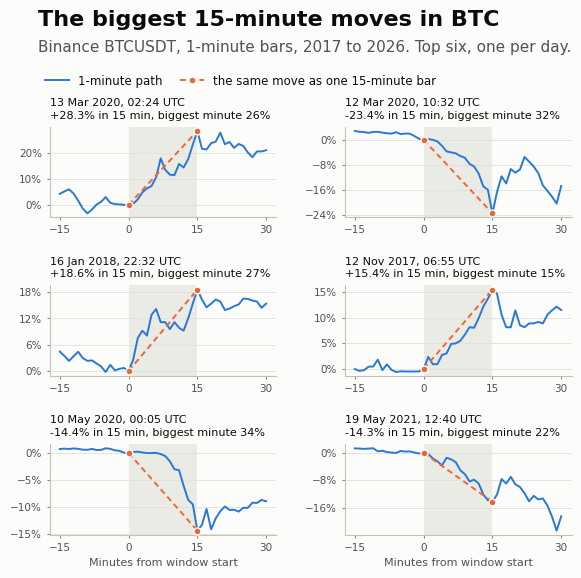

In [2]:
WINDOW, CONTEXT = 15, 15
events = largest_moves(np.log(close["BTCUSDT"]), WINDOW, top=50, context_minutes=CONTEXT)

fig = jp.event_panel(
    events.iloc[:6], WINDOW, CONTEXT,
    title="The biggest 15-minute moves in BTC",
    subtitle="Binance BTCUSDT, 1-minute bars, 2017 to 2026. Top six, one per day.",
)
jp.save(fig, "01_event_panel");

In [3]:
table = events.drop(columns=["path_pct", "end"]).copy()
table["window_return"] = 100 * table["window_return"]
table["largest_minute"] = 100 * table["largest_minute"]
table["largest_minute_share"] = 100 * table["largest_minute_share"]
table.index = table.index.strftime("%Y-%m-%d %H:%M")
table.columns = ["15-min move (%)", "largest 1-min return (%)", "its share of the move (%)", "minutes to half the move"]
table.head(12).round(1)

,15-min move (%),largest 1-min return (%),its share of the move (%),minutes to half the move
start,,,,
2020-03-13 02:24,28.3,7.2,25.6,7
2020-03-12 10:32,-23.4,-7.5,32.1,13
2018-01-16 22:32,18.6,5.0,26.8,5
2017-11-12 06:55,15.4,2.4,15.3,10
2020-05-10 00:05,-14.4,-4.9,33.9,13
2021-05-19 12:40,-14.3,-3.2,22.2,10
2019-06-26 20:29,-14.1,-4.5,31.7,11
2021-12-04 05:12,-14.0,-4.6,33.2,14
2018-01-11 04:40,13.1,3.3,25.2,7


In [4]:
share = 100 * events["largest_minute_share"]
print(f"Top {len(events)} fifteen-minute moves in BTC, {START} to {END}")
print(f"Largest single minute as a share of the move: median {share.median():.0f}%, "
      f"max {share.max():.0f}%, above 50% in {int((share > 50).sum())} of {len(share)} events")
print(f"Minutes needed to cover half the move: median {events['minutes_to_half'].median():.0f}")

Top 50 fifteen-minute moves in BTC, 2017-08 to 2026-10
Largest single minute as a share of the move: median 29%, max 93%, above 50% in 4 of 50 events
Minutes needed to cover half the move: median 10


In the six largest moves in Bitcoin's history the biggest minute carries between a sixth and a third of the move, and it takes five to fourteen minutes to cover half of it. Across the top fifty, one minute carries more than half the move in four cases; the median is under a third. On a 15-minute chart each of these is one candle, and to a test that only sees candles, one candle is a jump.

## 2. What the standard jump test sees, bar size by bar size

Log price with stochastic volatility and finite-activity jumps:

$$X_t = X_0 + \int_0^t \mu_s\,ds + \int_0^t \sigma_s\,dW_s + \sum_{k=1}^{N_t} J_k$$

Over one day with $n$ intraday returns $r_i$, realized variance picks up both components, bipower variation only the continuous one:

$$\mathrm{RV} = \sum_{i=1}^{n} r_i^2 \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds + \sum_{k} J_k^2
\qquad
\mathrm{BV} = \frac{\pi}{2}\,\frac{n}{n-1}\sum_{i=2}^{n} |r_i|\,|r_{i-1}| \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds$$

A jump sits in one return only, so the product of adjacent absolute returns kills it in the limit. The relative jump measure is the gap,

$$\mathrm{RJ} = \frac{\mathrm{RV} - \mathrm{BV}}{\mathrm{RV}},$$

and the Barndorff-Nielsen and Shephard test in the ratio form of Huang and Tauchen (2005) is asymptotically standard normal on a day without jumps:

$$z = \frac{\mathrm{RJ}}{\sqrt{\left(\frac{\pi^2}{4} + \pi - 5\right)\frac{1}{n}\,\max\!\left(1, \frac{\mathrm{TQ}}{\mathrm{BV}^2}\right)}}$$

with TQ the tripower quarticity. The limit needs volatility to be roughly constant across *adjacent* returns. A move that unfolds over several minutes but sits inside one bar breaks that assumption, and the whole move is booked to the jump component.

The jump share below is $1 - \sum \mathrm{BV} / \sum \mathrm{RV}$ over all days, so it is not floored at zero. Days with a data gap longer than five minutes are dropped.

In [5]:
INTERVALS = {"1m": 1, "5m": 5, "15m": 15, "30m": 30, "1h": 60}
EMP_LABELS = list(INTERVALS)

grids = {s: to_daily_grid(c) for s, c in close.items()}
empirical = {s: jump_summary(g.to_numpy(), list(INTERVALS.values())) for s, g in grids.items()}
for s, g in grids.items():
    print(f"{s}: {len(g):,} complete days")

emp_table = pd.concat(
    {"Jump share of variance (%)": pd.DataFrame({s[:3]: 100 * r["jump_share"] for s, r in empirical.items()}, index=EMP_LABELS),
     "Days flagged at 1% (%)": pd.DataFrame({s[:3]: 100 * r["days_flagged"] for s, r in empirical.items()}, index=EMP_LABELS)},
    axis=1)
emp_table.round(1).rename_axis("Sampling interval")

BTCUSDT: 3,315 complete days
ETHUSDT: 3,315 complete days


Jump share of variance (%)       Days flagged at 1% (%)      
                                         BTC   ETH                    BTC   ETH
Sampling interval                                                              
1m                                       8.7   8.6                   34.5  34.2
5m                                       7.0   6.1                   20.2  20.3
15m                                      7.5   7.2                   14.4  14.5
30m                                     10.2   9.6                   12.9  14.1
1h                                      15.4  13.5                   11.6  11.3

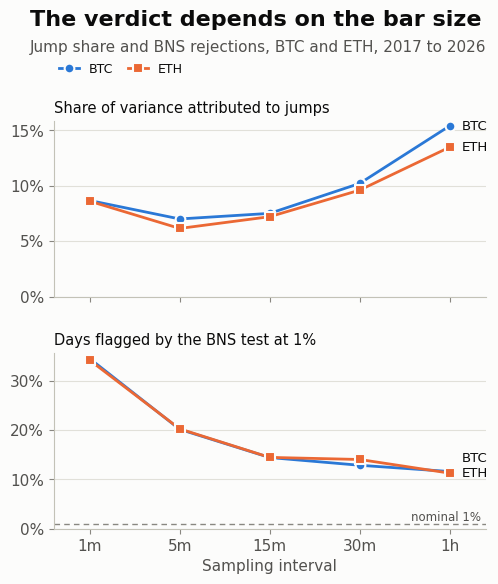

In [6]:
curves = {
    "BTC": {"x": range(len(EMP_LABELS)), "jump_share": 100 * empirical["BTCUSDT"]["jump_share"],
            "days_flagged": 100 * empirical["BTCUSDT"]["days_flagged"], "color": jp.BLUE, "marker": "o"},
    "ETH": {"x": range(len(EMP_LABELS)), "jump_share": 100 * empirical["ETHUSDT"]["jump_share"],
            "days_flagged": 100 * empirical["ETHUSDT"]["days_flagged"], "color": jp.ORANGE, "marker": "s"},
}
fig = jp.sampling_curves(
    curves, EMP_LABELS,
    title="The verdict depends on the bar size",
    subtitle="Jump share and BNS rejections, BTC and ETH, 2017 to 2026",
)
jp.save(fig, "01_jump_share_by_sampling");

Two things to read off this chart.

- From hourly bars down to 5-minute bars the jump share halves. Same days, same prices, different clock. Between 5 minutes and 1 minute it ticks back up by under two points, and that small uptick is where the next two posts start.
- At 1-minute sampling the test rejects "no jumps" on a third of all days, against a nominal 1%. Part of that is real jumps, part of it is intraday seasonality of volatility, which also violates the locally-constant assumption. That is post 2.

## 3. Which way does the curve bend? A small simulation

From 1 hour down to 5 minutes the empirical curve falls as the bar gets finer. Is that what a continuous path does, or what a jump process does? Three simulated worlds on a 5-second grid, sharing the same daily volatility level and intraday pattern at 50% annualised volatility:

- **Bursts, no jumps.** A continuous path where volatility spikes to 10 to 25 times its level about every other day and decays with a 60-second half-life. True jump share: 0%.
- **Poisson jumps.** No bursts; compound Poisson jumps with Gaussian sizes at the same rate, carrying 10% of total variance.
- **Variance gamma.** Brownian motion run on a gamma clock, $X_t = \sigma\, W_{G_t}$ with $G$ a gamma subordinator. Purely discontinuous, infinitely many small jumps, no diffusion component at all. Its true "jump share" is 100%.

As sampling gets finer, bipower variation converges to the integrated variance of the *continuous* part. For the bursts world that is everything, so the jump share falls to zero. For the Poisson world it is 90%, so the share settles near 10%. For variance gamma there is no continuous part, so the share rises towards 100%. The direction of the empirical curve is therefore evidence about which description fits.

One caveat on the third world: plain variance gamma has independent increments, so it cannot cluster activity in time. A stochastic clock is needed for that, which is where post 4 picks up.

In [7]:
DT = 5  # seconds
SIM_INTERVALS = {"5s": 5, "15s": 15, "1m": 60, "5m": 300, "15m": 900, "30m": 1800, "1h": 3600}
SIM_LABELS = list(SIM_INTERVALS)
sim_steps = [s // DT for s in SIM_INTERVALS.values()]

worlds = {
    "Bursts, no jumps": simulate_log_prices("bursts", n_days=250, dt_seconds=DT, seed=0),
    "Poisson jumps": simulate_log_prices("jumps", n_days=250, dt_seconds=DT, seed=0),
    "Variance gamma": simulate_log_prices("vg", n_days=250, dt_seconds=DT, seed=0),
}
sim = {name: jump_summary(lp, sim_steps) for name, lp in worlds.items()}
sim_table = pd.DataFrame({name: 100 * r["jump_share"] for name, r in sim.items()}, index=SIM_LABELS)
sim_table.round(1).rename_axis("Sampling interval")

,"Bursts, no jumps",Poisson jumps,Variance gamma
Sampling interval,,,
5s,0.5,9.0,99.1
15s,0.7,8.7,97.3
1m,2.3,8.2,89.8
5m,4.3,7.5,63.9
15m,5.0,6.7,36.8
30m,4.9,6.6,23.2
1h,5.0,7.5,12.9


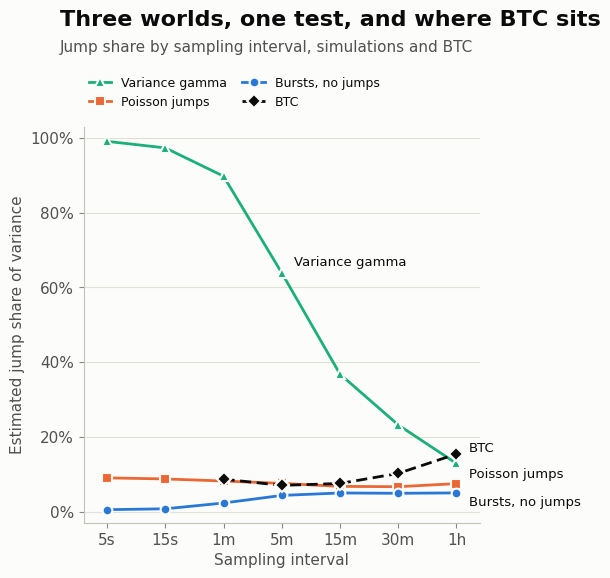

In [8]:
x_sim = list(range(len(SIM_LABELS)))
x_emp = [SIM_LABELS.index(k) for k in EMP_LABELS]
series = [
    {"name": "Variance gamma", "x": x_sim, "y": 100 * sim["Variance gamma"]["jump_share"], "color": jp.AQUA, "marker": "^", "label_at": 3, "dy": 8},
    {"name": "Poisson jumps", "x": x_sim, "y": 100 * sim["Poisson jumps"]["jump_share"], "color": jp.ORANGE, "marker": "s", "dy": 7},
    {"name": "Bursts, no jumps", "x": x_sim, "y": 100 * sim["Bursts, no jumps"]["jump_share"], "color": jp.BLUE, "marker": "o", "dy": -7},
    {"name": "BTC", "x": x_emp, "y": 100 * empirical["BTCUSDT"]["jump_share"], "color": jp.INK, "marker": "D", "ls": (0, (4, 2)), "dy": 4},
]
fig = jp.worlds_plot(
    series, SIM_LABELS,
    title="Three worlds, one test, and where BTC sits",
    subtitle="Jump share by sampling interval, simulations and BTC",
)
jp.save(fig, "01_three_worlds");

From 1 hour down to 5 minutes, BTC bends the way the continuous worlds do, not the way a pure-jump process does. That rules out "BTC is variance gamma with nothing else" on this evidence. Between 5 minutes and 1 minute the curve ticks up by under two points, which is the direction a pure-jump component would push it. Whether that uptick is intraday seasonality, microstructure noise or genuine small jumps is exactly what posts 2 and 3 are for.

## 4. Caveats

- A smooth path at 1 minute does not rule out small jumps at tick level. It rules out one large discontinuity.
- Microstructure noise distorts both RV and BV at the finest frequencies. Tick-level work needs noise-robust estimators such as pre-averaging (post 3).
- With 1-minute bars only the right-hand part of the sampling curve is visible. The simulation shows what the left-hand part can look like, under hand-picked parameters.
- The simulation is a sanity check, not a model of BTC: no leverage effect, no microstructure noise, no clustering of activity in the variance gamma world.
- Intraday seasonality of volatility inflates the rejection rate on its own, at every sampling interval (post 2).

## 5. Takeaways

1. The largest 15-minute moves in BTC are multi-minute slides, not discontinuities. The biggest single minute carries a third of the move at most.
2. A bar-based jump test cannot see the difference. Its jump share and its rejection rate are properties of the bar size as much as of the price.
3. From hourly to 5-minute bars the empirical jump share falls, which is the signature of a continuous path with bursts, not of a pure-jump process. The small uptick at 1 minute is the open question for posts 2 and 3.
4. On equities and FX tick data, Christensen, Oomen and Podolskij found that jumps account for about 1% of total price variation, an order of magnitude below estimates from lower-frequency data. BTC at 1 minute is still well above that, and posts 2 and 3 take the next two bites out of it.

## Equation images for the post

LinkedIn does not render LaTeX, so the key equations are exported as images.

In [9]:
jp.render_equation(r"\mathrm{RV}=\sum_{i=1}^{n} r_i^2\ \rightarrow\ \int_0^1\sigma_s^2\,ds+\sum_k J_k^2",
                   "01_eq_rv", "Realized variance captures diffusion and jumps")
jp.render_equation(r"\mathrm{BV}=\dfrac{\pi}{2}\sum_{i=2}^{n}|r_i|\,|r_{i\!-\!1}|\ \rightarrow\ \int_0^1\sigma_s^2\,ds",
                   "01_eq_bv", "Bipower variation captures diffusion only")
jp.render_equation(r"\mathrm{RJ}=\dfrac{\mathrm{RV}-\mathrm{BV}}{\mathrm{RV}}",
                   "01_eq_rj", "Relative jump measure: the share of variance attributed to jumps")
jp.render_equation(r"X_t=\sigma\,W_{G_t},\qquad G_t\sim\Gamma(t/\nu,\ \nu)",
                   "01_eq_vg", "Variance gamma: Brownian motion on a gamma clock, no diffusion part");

## References

- Christensen, K., Oomen, R. C. A. and Podolskij, M. (2014). Fact or friction: Jumps at ultra high frequency. *Journal of Financial Economics*, 114(3), 576-599. [arXiv:2602.10925](https://arxiv.org/abs/2602.10925) · [doi:10.1016/j.jfineco.2014.07.007](https://doi.org/10.1016/j.jfineco.2014.07.007)
- Barndorff-Nielsen, O. E. and Shephard, N. (2004). Power and bipower variation with stochastic volatility and jumps. *Journal of Financial Econometrics*, 2(1), 1-37. [doi:10.1093/jjfinec/nbh001](https://doi.org/10.1093/jjfinec/nbh001)
- Huang, X. and Tauchen, G. (2005). The relative contribution of jumps to total price variance. *Journal of Financial Econometrics*, 3(4), 456-499. [RePEc](https://ideas.repec.org/a/oup/jfinec/v3y2005i4p456-499.html)

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*